In [127]:
import json, re, time, math
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import sparse

# scikit-learn: usado só para dividir os dados e calcular métricas
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

SEED = 42                                   # semente fixa: resultados reprodutíveis
ARQ_ORIGINAL = "articles.csv"               # base completa baixada do Kaggle
ARQ_AMOSTRA = "articles_amostra_6000.csv"   # amostra tratada, criada pela célula de dados

# Paleta usada em todos os gráficos
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
CORES = [AZUL, LARANJA, VERDE, "#eda100", "#e87ba4"]


def encontrar_pasta_base():
    """
    Descobre a pasta onde está o articles.csv.

    O kernel pode ser aberto em notebooks/ ou em notebooks/classification/,
    então o arquivo original é procurado nas duas opções.
    """
    for pasta in (Path("."), Path("classification")):
        if (pasta / ARQ_ORIGINAL).exists():
            return pasta
    raise FileNotFoundError(f"'{ARQ_ORIGINAL}' não encontrado. Pasta atual: {Path.cwd()}")


def configurar_caminhos():
    """
    Define os caminhos da base original, da amostra e da pasta de figuras.

    A amostra fica na mesma pasta do original, que com certeza existe,
    e a pasta de figuras é criada se ainda não existir.
    """
    base = encontrar_pasta_base()
    fig = base / "figuras"
    fig.mkdir(parents=True, exist_ok=True)
    return base / ARQ_ORIGINAL, base / ARQ_AMOSTRA, fig


def configurar_exibicao():
    """Define o formato dos números e das tabelas impressas no notebook."""
    np.set_printoptions(precision=4, suppress=True)
    pd.set_option("display.width", 200)
    pd.set_option("display.max_columns", 20)


def configurar_graficos():
    """Aplica o estilo padrão dos gráficos: limpo, grade leve e títulos em negrito."""
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
        "axes.titleweight": "bold", "axes.titlesize": 11,
        "legend.frameon": False,
    })


def salvar(fig, nome):
    """Salva a figura em figuras/ para uso no relatório e nos slides."""
    fig.tight_layout()
    fig.savefig(FIG / nome, bbox_inches="tight", facecolor="white")


def metricas(y, p):
    """
    Calcula as métricas pedidas no enunciado (Aula 07; Géron cap. 3).

    y são os rótulos verdadeiros e p os rótulos previstos.
    """
    return {
        "Precision (macro)": precision_score(y, p, average="macro", zero_division=0),
        "Recall (macro)":    recall_score(y, p, average="macro", zero_division=0),
        "F1-micro":          f1_score(y, p, average="micro"),
        "F1-macro":          f1_score(y, p, average="macro"),
        "Acurácia":          accuracy_score(y, p),
    }


DADOS_ORIGINAL, DADOS, FIG = configurar_caminhos()
configurar_exibicao()
configurar_graficos()
RESULTADOS = {}   # números-chave, salvos em resultados.json no final

print("configuração pronta")
print("Pasta do Python:", Path.cwd())
print("Original:", DADOS_ORIGINAL, "| existe?", DADOS_ORIGINAL.exists())
print("Amostra: ", DADOS, "| existe?", DADOS.exists())

configuração pronta
Pasta do Python: /home/jovyan/work/ classification/notebooks/classification
Original: articles.csv | existe? True
Amostra:  articles_amostra_6000.csv | existe? False


## 1. Dataset

> **Enunciado:** escolher um dataset de classificação com ao menos 2.000 instâncias e no mínimo 5 classes, com texto não estruturado. Separar 20% para teste, 20% para validação e 60% para treino.

### Requisitos do enunciado × base escolhida

| Requisito | Exigido | Base escolhida | Atende? |
|---|---|---|:---:|
| Tipo de tarefa | Classificação | Classificação da editoria | ✅ |
| Nº de instâncias | ≥ 2.000 | 167.053 notícias | ✅ |
| Nº de classes | ≥ 5 | Editorias do jornal | ✅ |
| Tipo de dado | Texto não estruturado | Texto livre das notícias (português) | ✅ |
| Divisão | 60% / 20% / 20% | Treino / validação / teste | ✅ |

### Ficha da base

| Item | Descrição |
|---|---|
| **Nome** | News of the Brazilian Newspaper |
| **Autor / ano** | Santana (2019) |
| **Fonte** | Kaggle |
| **Origem das notícias** | Site da *Folha de S.Paulo* |
| **Período** | Janeiro de 2015 a setembro de 2017 |
| **Idioma** | Português |
| **Tamanho** | 167.053 notícias |
| **Variável-alvo** | Editoria (seção do jornal) |
| **Problema** | Prever a seção do jornal a partir do texto livre da notícia |

### Atributos de cada notícia

| Atributo | Descrição | Papel no problema |
|---|---|---|
| Título | Manchete da notícia | Texto de entrada (opcional) |
| Texto | Corpo da notícia | **Entrada principal** |
| Data | Data de publicação | Metadado |
| Link | URL da notícia no site | Metadado |
| Editoria | Seção em que foi publicada | **Alvo (classe)** |

### Divisão dos dados

| Conjunto | Proporção | Uso |
|---|:---:|---|
| Treino | 60% | Ajuste dos pesos da rede |
| Validação | 20% | Escolha de hiperparâmetros e *early stopping* |
| Teste | 20% | Avaliação final, usado uma única vez |

### 1.1 Carregamento da base original

In [130]:
def load_dataset(path: str):
    """Lê o CSV de notícias e retorna o DataFrame, sem nenhum efeito colateral além da leitura."""
    return pd.read_csv(path)

def summary_dataset(data: pd.DataFrame, n_editorias: int = 15) -> dict:
    """Retorna formato, colunas, período e as editorias mais frequentes da base."""
    return {
        "formato": data.shape,
        "colunas": list(data.columns),
        "período": (data.date.min(), data.date.max()),
        "editorias": data.category.value_counts().head(n_editorias),
    }

df = load_dataset(ARQ_ORIGINAL)
summary = summary_dataset(df)
print(summary)


{'formato': (167053, 6), 'colunas': ['title', 'text', 'date', 'category', 'subcategory', 'link'], 'período': ('2015-01-01', '2017-10-01'), 'editorias': category
poder             22022
colunas           21622
mercado           20970
esporte           19730
mundo             17130
cotidiano         16967
ilustrada         16345
opiniao            4525
paineldoleitor     4011
saopaulo           3955
tec                2260
tv                 2142
educacao           2118
turismo            1903
ilustrissima       1411
Name: count, dtype: int64}


### 1.2 Seleção das editorias e limpeza

A base tem 48 editorias, de tamanhos muito desiguais. A seleção seguiu três critérios:

1. **Editorias de assunto, e não de formato.** Colunas, opinião e painel do leitor reúnem textos opinativos sobre qualquer assunto (política, economia, cultura…), então o rótulo não descreve o conteúdo. Essas editorias foram descartadas.
2. **Editorias grandes.** Ficaram as seis maiores editorias de assunto, todas com mais de 15 mil notícias:
   - **poder** (política)
   - **mercado** (economia)
   - **esporte**
   - **mundo** (internacional)
   - **cotidiano** (cidades, segurança, serviços)
   - **ilustrada** (cultura e entretenimento)
3. **Limpeza.** Foram removidas as notícias sem texto, os textos com menos de 30 palavras (em geral só um link ou uma legenda) e as duplicatas.

A remoção de duplicatas evita *data leakage* (Aula 09). Se a mesma notícia aparecesse duas vezes, uma cópia poderia cair no treino e a outra no teste, e o modelo seria avaliado em algo que já viu.

### 1.3 Amostragem

Depois da limpeza restam mais de 112 mil notícias. Dessas, foi sorteada uma **amostra estratificada de 6.000 notícias**, que mantém a proporção de cada editoria.

Esse tamanho atende ao enunciado (≥ 2.000) e mantém o custo dos experimentos viável: a árvore de decisão implementada em NumPy é treinada mais de 30 vezes, e cada treino com 3.600 notícias leva cerca de um minuto.

In [149]:
sections = ["poder", "mercado", "esporte", "mundo", "cotidiano", "ilustrada"]
minimun_size_words = 30
sample_size = 6000
resultados = dict()

def noticies_filter(dados: pd.DataFrame, sections: list, minimum_size_words: int = 30) -> tuple:
    """df, steps = get_sample(DADOS_ORIGINAL, DADOS)
df = create_column_documento(df)

        Aplica os filtros de limpeza e retorna (notícias filtratas, contagém após cada etapa).

        Mantém só as editorias escolhidas, remove notícias sem texto,
        textos curtos demais e textos duplicados.
    """

    # gera True/False para cada linha, coforme a editoria esteja ou não na lista.
    sel = dados[dados.category.isin(sections)]
    steps = {f"{len(sections)} editorias": len(sel)}
    print(f"È da categória: {passos['6 editorias']}")

    # dropna remove linhas com valor ausente (NaN).
    # subset=["text"] olha só a coluna text. Sem isso, a função removeria a linha se qualquer coluna estivesse vazia
    sel = sel.dropna(subset=["text"])
    steps["com texto"] = len(sel)
    print(f"Tem texto: {passos['com texto']}")

    # split quebra o texto em palavras, len conta quantas são, >= compara se o texto tem mais que palavras que o minimun_size_words = 30
    sel = sel[sel.text.str.split().str.len() >= minimum_size_words]
    steps[f">= {minimum_size_words} palavras"] = len(sel)
    print(f"Minimo palavras: {passos[f'>= {minimum_size_words} palavras']}")

    sel = sel.drop_duplicates(subset="text")
    steps["sem duplicatas"] = len(sel)
    print(f"Sem duplicações: {passos['sem duplicatas']}")

    return sel, passos


def sample(sel: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """Sorteia n notícias mantendo a proporção de cada editoria (amostragem estratificada)"""
    amostra, _ = train_test_split(sel, train_size=n, stratify=sel.category, random_state=SEED)
    return amostra[["title", "text", "date", "category"]].reset_index(drop=True)

def create_column_documento(df: pd.DataFrame) -> pd.DataFrame:
    """
    Retorna uma cópia com a coluna 'documento' (título + corpo), o texto que o modelo lê
    """
    return df.assign(documento=df.title.fillna("") + ". " + df.text)


def get_sample(path_original, path_sample) -> tuple:
    """
    Lê a amostra se ela já existir; senão, cria a partir da base original e salva.

    Retorna (amostra, passos); passos é None quando a amostra apenas foi lida.
    """

    if path_sample.exists():
        return pd.read_csv(path_sample), None

    dados = load_dataset(path_original)
    sel, steps = noticies_filter(dados, sections, minimum_size_words)
    samp = sample(sel, sample_size, SEED)
    samp.to_csv(path_sample, index=False)
    steps["amostra"] = len(samp)

    return samp, steps


df, steps = get_sample(DADOS_ORIGINAL, DADOS)
df = create_column_documento(df)

if steps is not None:
    print("notícias após cada etapa:", steps)
    resultados["dados"] = steps

print(f"\nAmostra: {len(df)} notícias, {df.category.nunique()} classes")
print(df.category.value_counts().to_string())



Amostra: 6000 notícias, 6 classes
category
poder        1174
mercado      1119
esporte      1054
mundo         915
cotidiano     906
ilustrada     832


### 1.4 Divisão *hold-out* 60/20/20 estratificada (Géron, cap. 2; Aula 09)

| Conjunto | Proporção | Uso |
|---|---|---|
| **Treino** | 60% | Ajusta os parâmetros (pesos da regressão, cortes da árvore) e o vocabulário do TF-IDF. |
| **Validação** | 20% | Escolhe os hiperparâmetros (α, profundidade) e desenha as curvas de aprendizado. |
| **Teste** | 20% | Avaliação final, usada uma única vez por modelo. |

A amostragem estratificada mantém a proporção das classes igual nos três conjuntos. Primeiro separamos 20% para teste. Do restante (80%), 25% vão para validação, ou seja, 20% do total.

In [157]:
# O train_test_split só sabe cortar em duas partes. Para chegar a 60\20\20, o código corta duas vezes:
treino_val, teste = train_test_split(df, test_size=0.20, stratify=df.category, random_state=SEED)
treino, val = train_test_split(treino_val, test_size=0.25, stratify=treino_val.category, random_state=SEED)
y_tr, y_va, y_te = treino.category.values, val.category.values, teste.category.values
CLASSES = sorted(df.category.unique())

tabela = pd.DataFrame({"treino": treino.category.value_counts(), "validação": val.category.value_counts(),
                       "teste": teste.category.value_counts()}).reindex(CLASSES)

tabela.loc["Total"] = tabela.sum()
print(tabela.to_string())
print("\nproporção de cada classe (%):")
print((tabela.drop("Total") / tabela.drop("Total").sum() * 100).round(1).to_string())

           treino  validação  teste
category                           
cotidiano     544        181    181
esporte       632        211    211
ilustrada     500        166    166
mercado       671        224    224
mundo         549        183    183
poder         704        235    235
Total        3600       1200   1200

proporção de cada classe (%):
           treino  validação  teste
category                           
cotidiano    15.1       15.1   15.1
esporte      17.6       17.6   17.6
ilustrada    13.9       13.8   13.8
mercado      18.6       18.7   18.7
mundo        15.2       15.2   15.2
poder        19.6       19.6   19.6


## 2. Representação TF-IDF

> **Enunciado:** aplicar a estratégia de TF-IDF sobre os dados não estruturados.

### 2.1 Teoria (Aula 06; Manning et al., cap. 6)

Os algoritmos trabalham com números, mas uma notícia é uma sequência de palavras de tamanho variável. O modelo **bag-of-words** transforma cada documento num vetor com um componente por termo do vocabulário.

A frequência pura do termo (TF) tem dois problemas apontados na Aula 06: um termo frequente em *todos* os documentos (como "presidente" ou "governo" em um jornal) recebe peso alto sem discriminar nada, e um termo raro no corpus deveria valer mais. O **IDF** corrige isso:

$$\mathrm{idf}(t) = 1 + \ln\frac{n}{n_t} \qquad \mathrm{tfidf}(d,t) = \frac{\mathrm{tf}(d,t)\cdot \mathrm{idf}(t)}{\sqrt{\sum_j \big(\mathrm{tf}(d,t_j)\cdot \mathrm{idf}(t_j)\big)^2}}$$

onde $n$ é o número de documentos e $n_t$ o número de documentos que contêm o termo $t$. A divisão final (norma L2) compensa o tamanho diferente das notícias.

In [179]:
STOPWORDS_PT = set("""a afirma afirmou agora ainda ali além ano anos ao aos apenas após aquela aquelas aquele aqueles aqui aquilo as assim até bem bom cada com como contra da daquela daquele das de dela delas dele deles depois desde dessa desse desta deste deve devem disse disso disto diz dizer do dos durante e ela elas ele eles em enquanto entre então era eram essa essas esse esses esta estar estas estava estavam este esteja estejam estes esteve estive estivemos estiveram estivesse estivessem está estão eu faz fazer feira feito fez foi fomos for foram forem fosse fossem fui haja hajam havia haviam hei houve houvemos houveram houvesse houvessem há isso isto já lhe lhes lá mais mas me menos mesmo meu meus minha minhas muito na nada nas nem nessa nessas nesse nesses nesta nestas neste nestes ninguém no nos nossa nossas nosso nossos num numa não nós o onde os ou outra outras outro outros para pela pelas pelo pelos pode podem poderia pois por porque porém quais qual qualquer quando quanto quantos quase que quem se segundo seja sejam sem sempre sendo ser seria seriam será serão seu seus sido sobre somos sou sua suas são só também te tem temos tenha tenham tenho ter teu teus teve tinha tinham tive tivemos tiveram tivesse tivessem toda todas todo todos tu tua tuas tudo tão tém têm um uma umas uns vai vez vezes você vocês vos vão à às é""".split())

TOKEN = re.compile(r"[^\W\d_]{2,}")          # palavras com 2+ letras, inclusive acentuadas


def tokenizar(texto, stopwords=STOPWORDS_PT):
    return [t for t in TOKEN.findall(texto.lower()) if t not in stopwords]


print(tokenizar("O ministro da Fazenda afirmou nesta terça-feira que a inflação caiu 0,5%."))


class TfidfProprio:
    def __init__(self, min_df=3, max_df=0.90, max_features=3000):
        self.min_df, self.max_df, self.max_features = min_df, max_df, max_features

    def fit(self, textos):
        docs = [tokenizar(t) for t in textos]
        n = len(docs)
        df = Counter()                       # nº de documentos em que cada termo aparece
        cf = Counter()                       # frequência total do termo no corpus
        for d in docs:
            df.update(set(d)); cf.update(d)
        self.n_termos_brutos_ = len(df)
        candidatos = [t for t, v in df.items() if v >= self.min_df and v / n <= self.max_df]
        candidatos.sort(key=lambda t: (-cf[t], t))
        termos = sorted(candidatos[:self.max_features])
        self.vocabulario_ = {t: i for i, t in enumerate(termos)}
        self.termos_ = np.array(termos)
        n_te = np.array([df[t] for t in termos], dtype=float)
        self.idf_ = 1.0 + np.log(n / n_te)
        return self

    def transform(self, textos):
        linhas, cols, vals = [], [], []
        for i, t in enumerate(textos):
            tf = Counter(w for w in tokenizar(t) if w in self.vocabulario_)
            for termo, f in tf.items():
                linhas.append(i); cols.append(self.vocabulario_[termo]); vals.append(f)
        X = sparse.csr_matrix((vals, (linhas, cols)), shape=(len(textos), len(self.vocabulario_)), dtype=float)
        X = X.multiply(self.idf_).tocsr()                      # tf · idf
        normas = np.sqrt(np.asarray(X.multiply(X).sum(axis=1))).ravel()
        normas[normas == 0] = 1.0
        return sparse.diags(1.0 / normas) @ X                  # normalização L2

    def fit_transform(self, textos):
        return self.fit(textos).transform(textos)

['ministro', 'fazenda', 'terça', 'inflação', 'caiu']


In [180]:
tfidf = TfidfProprio(min_df=3, max_df=0.90, max_features=3000)
X_tr = tfidf.fit_transform(treino.documento)     # fit SÓ no treino
X_va = tfidf.transform(val.documento)
X_te = tfidf.transform(teste.documento)
VOCAB = tfidf.termos_

print(f"vocabulário: {tfidf.n_termos_brutos_} termos antes dos cortes → {X_tr.shape[1]} depois")
print(f"matrizes: treino {X_tr.shape}, validação {X_va.shape}, teste {X_te.shape}")
print(f"esparsidade do treino: {1 - X_tr.nnz / np.prod(X_tr.shape):.1%} "
      f"(em média {X_tr.nnz / X_tr.shape[0]:.0f} termos não nulos por notícia)")
ordem = np.argsort(tfidf.idf_)
print("menor idf:", [(str(VOCAB[i]), round(float(tfidf.idf_[i]), 2)) for i in ordem[:4]])
print("maior idf:", [(str(VOCAB[i]), round(float(tfidf.idf_[i]), 2)) for i in ordem[-4:]])

vocabulário: 56465 termos antes dos cortes → 3000 depois
matrizes: treino (3600, 3000), validação (1200, 3000), teste (1200, 3000)
esparsidade do treino: 96.6% (em média 102 termos não nulos por notícia)
menor idf: [('presidente', 1.95), ('dois', 2.04), ('governo', 2.12), ('país', 2.13)]
maior idf: [('caminhoneiros', 6.89), ('fidel', 7.11), ('tributáveis', 7.4), ('sep', 7.4)]


## 3. Estudo introdutório da base

> **Enunciado:** fazer um estudo introdutório sobre a base de dados.

### 3.1 Distribuição das classes

category
cotidiano     906
esporte      1054
ilustrada     832
mercado      1119
mundo         915
poder        1174
Name: count, dtype: int64
[ 906 1054  832 1119  915 1174]


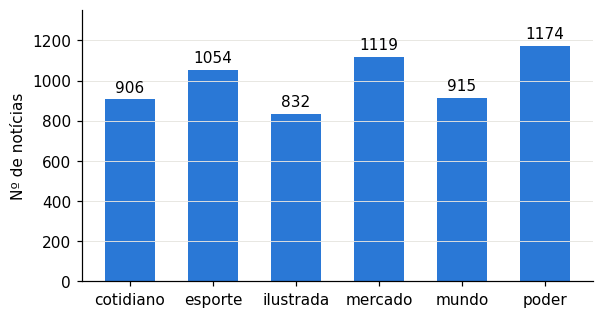

In [184]:
cont = df.category.value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6, 3.2))
# Classes, quantidade de noticias em cada classe.
barras = ax.bar(CLASSES, cont.values, color=AZUL, width=0.6)
ax.bar_label(barras, padding=3)
ax.set_ylabel("Nº de notícias");
ax.set_ylim(0, cont.max() * 1.15)
ax.grid(axis="x", visible=False)


print(cont)
print(cont.values)

As classes são **moderadamente desbalanceadas**: *poder*, a maior, tem 1,41 vez o tamanho de *ilustrada*, a menor. A amostra preserva as proporções da base original. Por isso a métrica principal do trabalho é o **F1-macro**, que dá o mesmo peso a todas as classes (Aula 07).

### 3.2 Tamanho dos textos

## Contar palavras por documento

`df.documento` é uma **Series de strings**. O acessor `.str` aplica operações de string **elemento a elemento**, de forma vetorizada (sem precisar escrever um loop).

| Etapa | O que faz |
|---|---|
| `.str.split()` | Divide cada texto nos espaços em branco, gerando uma **lista de palavras** |
| `.str.len()` | Retorna o tamanho de cada lista, ou seja, o **número de palavras** |

O resultado é salvo em uma nova coluna do DataFrame:

```python
df["n_palavras"] = df.documento.str.split().str.len()
```

## Estatísticas por classe

- `groupby("category")` separa as linhas por **classe**
- `.n_palavras` seleciona a coluna de interesse
- `.describe()` calcula, para cada grupo: `count`, `mean`, `std`, `min`, `25%`, `50%`, `75%`, `max`

Desse resumo, ficamos só com 4 colunas:

| Coluna | Significado |
|---|---|
| `mean` | Média |
| `50%` | Mediana |
| `min` | Mínimo |
| `max` | Máximo |

Por fim, `.round(0)` arredonda para inteiros e `.to_string()` imprime a tabela inteira, sem os cortes do pandas.

```python
print(
    df.groupby("category")
      .n_palavras
      .describe()[["mean", "50%", "min", "max"]]
      .round(0)
      .to_string()
)
```

                 mean    50%   min     max
category                                  
cotidiano  431.780353  389.0  54.0  1947.0
esporte    364.722960  309.0  47.0  1876.0
ilustrada  404.379808  355.0  39.0  2929.0
mercado    479.055407  422.0  47.0  7715.0
mundo      476.198907  421.0  48.0  1908.0
poder      477.020443  430.0  42.0  2734.0

geral: média 441, mediana 392 palavras


Text(0.5, 1.0, 'Tamanho dos textos por classe (sem outliers)')

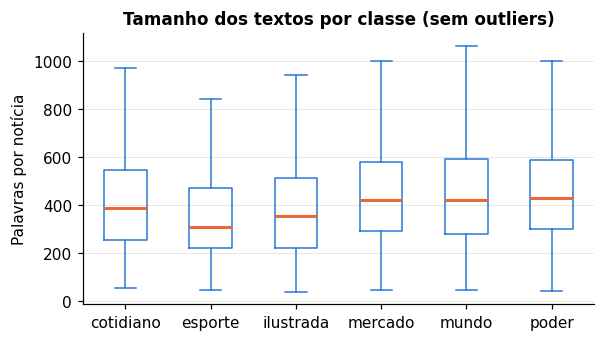

In [236]:
df["n_palavras"] = df.documento.str.split().str.len()
print(df.groupby("category").n_palavras.describe()[["mean", "50%", "min", "max"]])
print(f"\ngeral: média {df.n_palavras.mean():.0f}, mediana {df.n_palavras.median():.0f} palavras")

# Boxplot por classse
fig, ax = plt.subplots(figsize=(6, 3.2))

ax.boxplot(
    [df[df.category == c].n_palavras for c in CLASSES],
    labels=CLASSES,
    showfliers=False,
    medianprops=dict(color=LARANJA, linewidth=2),
    boxprops=dict(color=AZUL),
    whiskerprops=dict(color=AZUL),
    capprops=dict(color=AZUL),
)

ax.set_ylabel("Palavras por notícia")
ax.grid(axis="x", visible=False)
ax.set_title("Tamanho dos textos por classe (sem outliers)")

As notícias têm em média 441 palavras (mediana de 392). *Poder*, *mercado* e *mundo* trazem os textos mais longos, com medianas acima de 420 palavras; *esporte* traz os mais curtos (mediana de 309). Como o TF-IDF normaliza cada vetor pela norma L2, o tamanho do texto não favorece nenhuma classe.

### 3.3 Vocabulário característico de cada classe

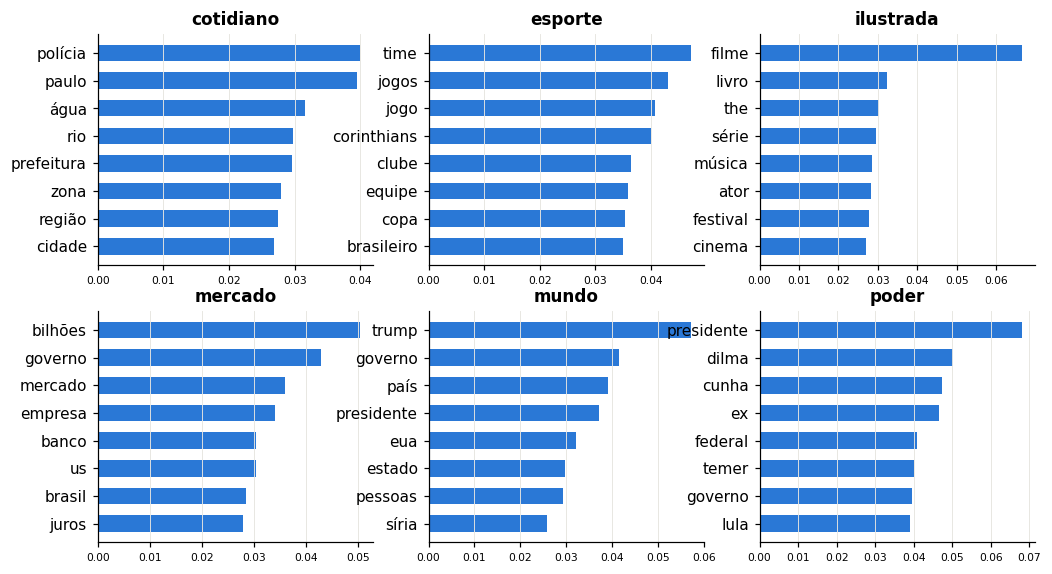

In [237]:
top_termos = {}
for c in CLASSES:
    media = np.asarray(X_tr[y_tr == c].mean(axis=0)).ravel()
    top_termos[c] = [(str(VOCAB[i]), float(media[i])) for i in np.argsort(-media)[:8]]


fig, axs = plt.subplots(2, 3, figsize=(11, 6))
for ax, c in zip(axs.ravel(), CLASSES):
    termos = top_termos[c][::-1]
    ax.barh([t for t, _ in termos], [v for _, v in termos], color=AZUL, height=0.6)
    ax.set_title(c)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=7)

Os termos já separam bem os assuntos e retratam o período de 2015 a 2017: *dilma*, *cunha*, *temer* e *lula* em **poder** (impeachment e Lava Jato); *trump*, *eua* e *síria* em **mundo**; *bilhões*, *juros* e *banco* em **mercado**; *time*, *jogos* e *corinthians* em **esporte**; *filme*, *livro* e *série* em **ilustrada**; *polícia*, *prefeitura* e *água* em **cotidiano** (a crise hídrica de São Paulo em 2015).

Há também **sobreposições** que antecipam os erros dos modelos:
- *governo* e *presidente* aparecem entre os principais termos de **poder**, **mercado** e **mundo**;
- *paulo* e *rio* aparecem em **cotidiano**, mas também em notícias de esporte (Olimpíada do Rio em 2016).

Dois termos mostram limites da tokenização: *us* em **mercado** vem de "US$", e *the* em **ilustrada** vem de títulos de filmes e discos em inglês.